### 1. Locate and Load the Raw Dataset
We will list files in the current directory to identify any training data CSV files, then load the data using `pandas`.

In [3]:
import os
import pandas as pd

# Recursively search for any CSV files in the workspace
csv_files = []
for root, dirs, files in os.walk('.'):
    for file in files:
        if file.endswith('.csv'):
            csv_files.append(os.path.join(root, file))

print("Found CSV files:", csv_files)

# Load the first available CSV file
if csv_files:
    data_path = csv_files[0]
    print(f"Loading {data_path}...")
    df = pd.read_csv(data_path)
else:
    print("Still no CSV files found. Please make sure the dataset is uploaded to the Colab environment.")

Found CSV files: ['./sample_data/california_housing_test.csv', './sample_data/mnist_train_small.csv', './sample_data/california_housing_train.csv', './sample_data/mnist_test.csv']
Loading ./sample_data/california_housing_test.csv...


### 2. High-Level Dataset Summary
We will inspect the shape, columns, missing values, and basic statistics of our dataset to understand its characteristics.

In [4]:
if 'df' in locals():
    print("=== Dataset Shape ===")
    print(f"{df.shape[0]} rows, {df.shape[1]} columns\n")

    print("=== Data Types & Missing Values ===")
    display(df.info())

    print("\n=== Preview of First 5 Rows ===")
    display(df.head())

    print("\n=== Descriptive Statistics ===")
    display(df.describe(include='all'))

=== Dataset Shape ===
3000 rows, 9 columns

=== Data Types & Missing Values ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           3000 non-null   float64
 1   latitude            3000 non-null   float64
 2   housing_median_age  3000 non-null   float64
 3   total_rooms         3000 non-null   float64
 4   total_bedrooms      3000 non-null   float64
 5   population          3000 non-null   float64
 6   households          3000 non-null   float64
 7   median_income       3000 non-null   float64
 8   median_house_value  3000 non-null   float64
dtypes: float64(9)
memory usage: 211.1 KB


None


=== Preview of First 5 Rows ===


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0



=== Descriptive Statistics ===


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,3000.00000
mean,-119.589200,35.63539,28.845333,2599.578667,529.950667,1402.798667,489.91200,3.807272,205846.27500
std,1.994936,2.12967,12.555396,2155.593332,415.654368,1030.543012,365.42271,1.854512,113119.68747
min,-124.180000,32.56000,1.000000,6.000000,2.000000,5.000000,2.00000,0.499900,22500.00000
25%,-121.810000,33.93000,18.000000,1401.000000,291.000000,780.000000,273.00000,2.544000,121200.00000
50%,-118.485000,34.27000,29.000000,2106.000000,437.000000,1155.000000,409.50000,3.487150,177650.00000
75%,-118.020000,37.69000,37.000000,3129.000000,636.000000,1742.750000,597.25000,4.656475,263975.00000
max,-114.490000,41.92000,52.000000,30450.000000,5419.000000,11935.000000,4930.00000,15.000100,500001.00000


### 3. Distribution of Median House Value
We will plot a histogram with a kernel density estimate (KDE) to visualize how house values are distributed across the dataset.

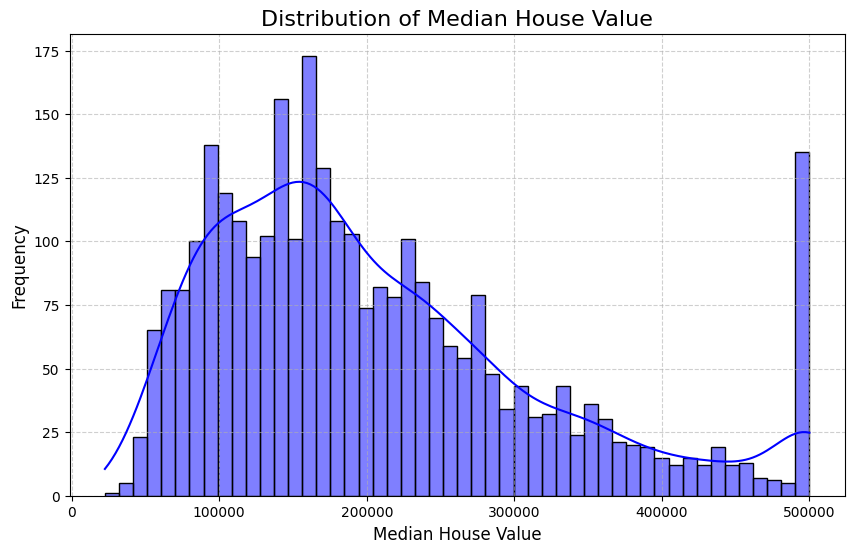

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'df' in locals() and 'median_house_value' in df.columns:
    plt.figure(figsize=(10, 6))
    sns.histplot(df['median_house_value'], kde=True, bins=50, color='blue')
    plt.title('Distribution of Median House Value', fontsize=16)
    plt.xlabel('Median House Value', fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()
else:
    print("Dataset or 'median_house_value' column is missing.")

### 4. Correlation Heatmap
We will calculate the pairwise correlation matrix of all numerical columns and visualize it using a heatmap.

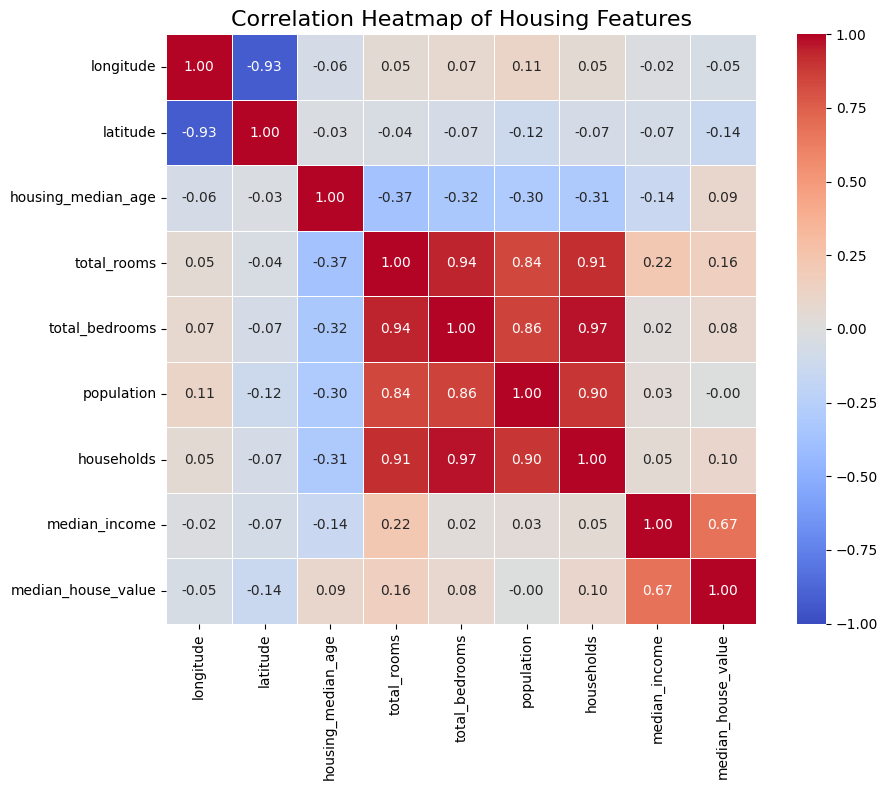

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'df' in locals():
    # Calculate correlation matrix for numerical features
    corr_matrix = df.corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, square=True, linewidths=0.5)
    plt.title('Correlation Heatmap of Housing Features', fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print("Dataset 'df' is not defined.")

### 5. Model Training: Linear Regression
We will build a simple linear regression model to predict `median_house_value` using the other features in the dataset. First, we split the data into training and validation sets, train the model, and evaluate its performance.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

if 'df' in locals():
    # Define features (X) and target variable (y)
    X = df.drop(columns=['median_house_value'])
    y = df['median_house_value']

    # Split data into training and validation sets (80% train, 20% validation)
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

    # Initialize and train the Linear Regression model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_val)

    # Evaluate the model
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2 = r2_score(y_val, y_pred)

    print("=== Model Evaluation ===")
    print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
    print(f"R-squared (R2) Score: {r2:.4f}")

    # Display feature coefficients
    coefficients = pd.DataFrame({
        'Feature': X.columns,
        'Coefficient': model.coef_
    }).sort_values(by='Coefficient', ascending=False)

    print("\n=== Feature Coefficients ===")
    display(coefficients)
else:
    print("Dataset 'df' is not defined. Please run previous cells first.")

=== Model Evaluation ===
Root Mean Squared Error (RMSE): $67,723.75
R-squared (R2) Score: 0.6358

=== Feature Coefficients ===


,Feature,Coefficient
7,median_income,39548.136989
2,housing_median_age,1147.116661
4,total_bedrooms,98.527564
6,households,61.434944
3,total_rooms,-7.886314
5,population,-40.504835
1,latitude,-43358.303029
0,longitude,-44009.947260


### 6. Residual Analysis
We will calculate the residuals ($y_{\text{val}} - y_{\text{pred}}$) and plot them against the predicted values to check for heteroscedasticity, non-linear patterns, or any systematic bias in our model predictions.

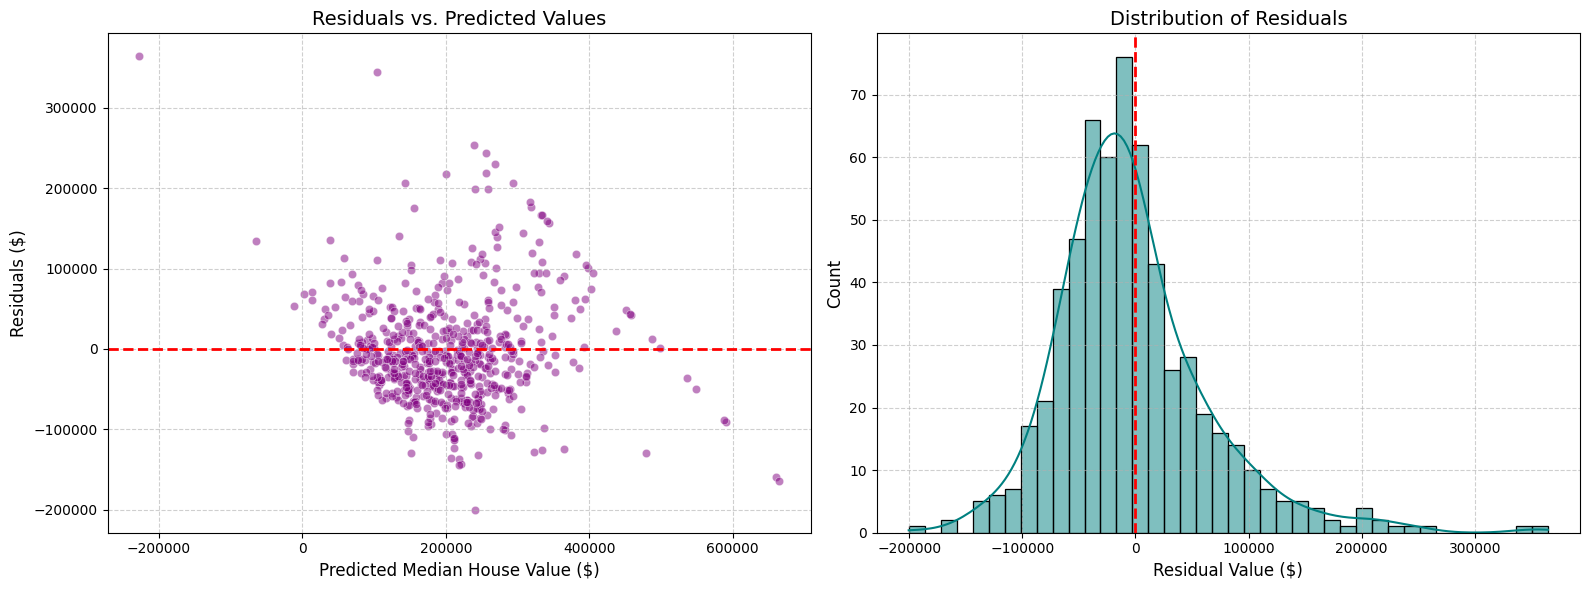

Mean of Residuals: $-3,123.46 (Close to 0 is ideal)
Standard Deviation of Residuals: $67,651.68


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

if 'y_val' in locals() and 'y_pred' in locals():
    # Calculate residuals
    residuals = y_val - y_pred

    # Set up the plotting area with two subplots
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # 1. Residuals vs. Predicted Values Plot
    sns.scatterplot(x=y_pred, y=residuals, alpha=0.5, color='purple', ax=axes[0])
    axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
    axes[0].set_title('Residuals vs. Predicted Values', fontsize=14)
    axes[0].set_xlabel('Predicted Median House Value ($)', fontsize=12)
    axes[0].set_ylabel('Residuals ($)', fontsize=12)
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # 2. Distribution of Residuals
    sns.histplot(residuals, kde=True, color='teal', bins=40, ax=axes[1])
    axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2)
    axes[1].set_title('Distribution of Residuals', fontsize=14)
    axes[1].set_xlabel('Residual Value ($)', fontsize=12)
    axes[1].set_ylabel('Count', fontsize=12)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

    # Print quick metrics on residual distribution
    mean_residual = np.mean(residuals)
    std_residual = np.std(residuals)
    print(f"Mean of Residuals: ${mean_residual:,.2f} (Close to 0 is ideal)")
    print(f"Standard Deviation of Residuals: ${std_residual:,.2f}")
else:
    print("y_val or y_pred variables are not available. Please run the model training step first.")

### 7. Training Model with Log-Transformed Target
Here we apply a log-transform to the target variable `median_house_value` to stabilize the variance of our residuals, retrain our model, and evaluate the performance of our new predictions.

=== Log-Transformed Model Evaluation (Converted Back) ===
Root Mean Squared Error (RMSE): $88,746.34 (Before: $67,723.75)
R-squared (R2) Score: 0.3746 (Before: 0.6358)


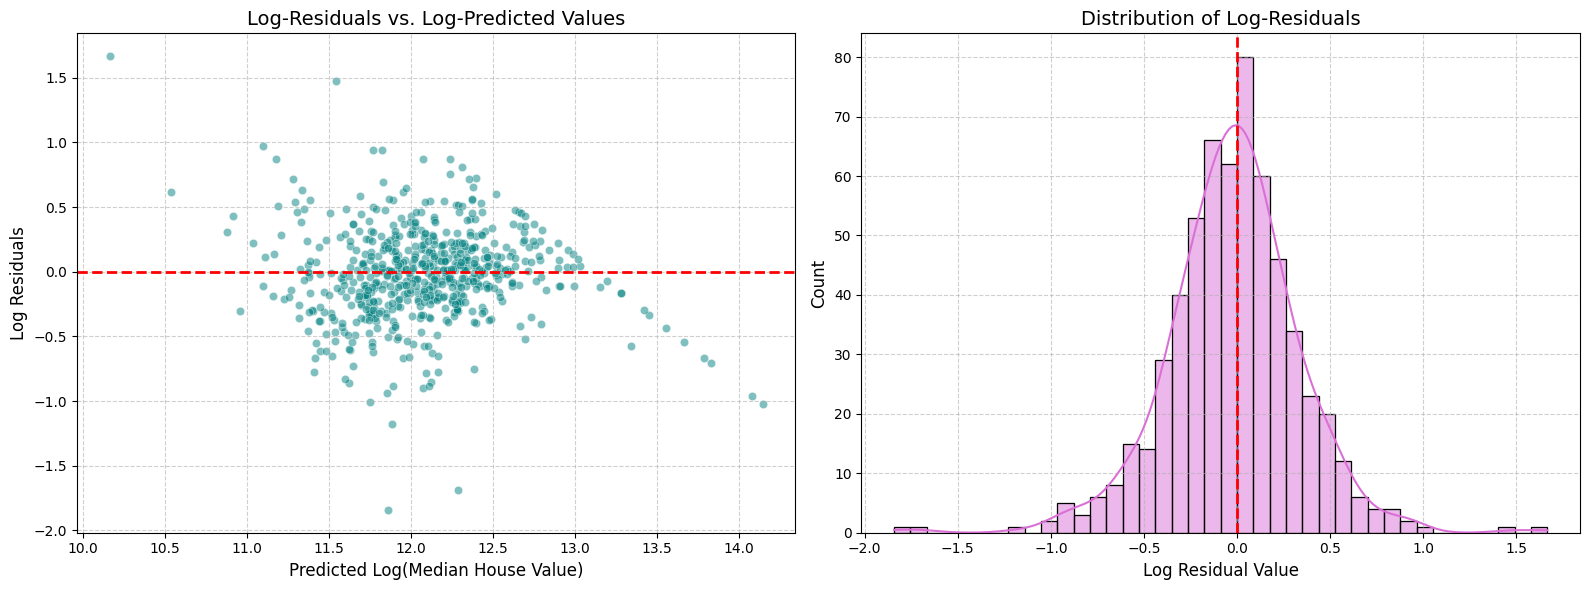

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if 'df' in locals():
    # Define features (X) and log-transformed target variable (y_log)
    # We use np.log1p (log(1 + x)) to avoid issues with potential 0 values
    X = df.drop(columns=['median_house_value'])
    y_log = np.log1p(df['median_house_value'])

    # Split data into training and validation sets (80% train, 20% validation)
    X_train, X_val, y_train_log, y_val_log = train_test_split(X, y_log, test_size=0.2, random_state=42)

    # Initialize and train the model
    log_model = LinearRegression()
    log_model.fit(X_train, y_train_log)

    # Predict in log scale
    y_pred_log = log_model.predict(X_val)

    # Convert predictions back to original scale
    y_val_orig = np.expm1(y_val_log)
    y_pred_orig = np.expm1(y_pred_log)

    # Evaluate the model on the original scale
    rmse_orig = np.sqrt(mean_squared_error(y_val_orig, y_pred_orig))
    r2_orig = r2_score(y_val_orig, y_pred_orig)

    print("=== Log-Transformed Model Evaluation (Converted Back) ===")
    print(f"Root Mean Squared Error (RMSE): ${rmse_orig:,.2f} (Before: $67,723.75)")
    print(f"R-squared (R2) Score: {r2_orig:.4f} (Before: 0.6358)")

    # Calculate residuals on the log scale
    log_residuals = y_val_log - y_pred_log

    # Plot new residuals
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # 1. Residuals vs. Predicted Values Plot (Log Scale)
    sns.scatterplot(x=y_pred_log, y=log_residuals, alpha=0.5, color='teal', ax=axes[0])
    axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
    axes[0].set_title('Log-Residuals vs. Log-Predicted Values', fontsize=14)
    axes[0].set_xlabel('Predicted Log(Median House Value)', fontsize=12)
    axes[0].set_ylabel('Log Residuals', fontsize=12)
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # 2. Distribution of Log-Residuals
    sns.histplot(log_residuals, kde=True, color='orchid', bins=40, ax=axes[1])
    axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2)
    axes[1].set_title('Distribution of Log-Residuals', fontsize=14)
    axes[1].set_xlabel('Log Residual Value', fontsize=12)
    axes[1].set_ylabel('Count', fontsize=12)
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()
else:
    print("Dataset 'df' is not defined. Please run previous cells first.")

### 8. Model Prediction Comparison: Actual vs. Predicted
We will plot the actual values against the predictions from both the original Linear Regression model and the log-transformed model to visually assess their alignment with the perfect prediction diagonal ($y=x$).

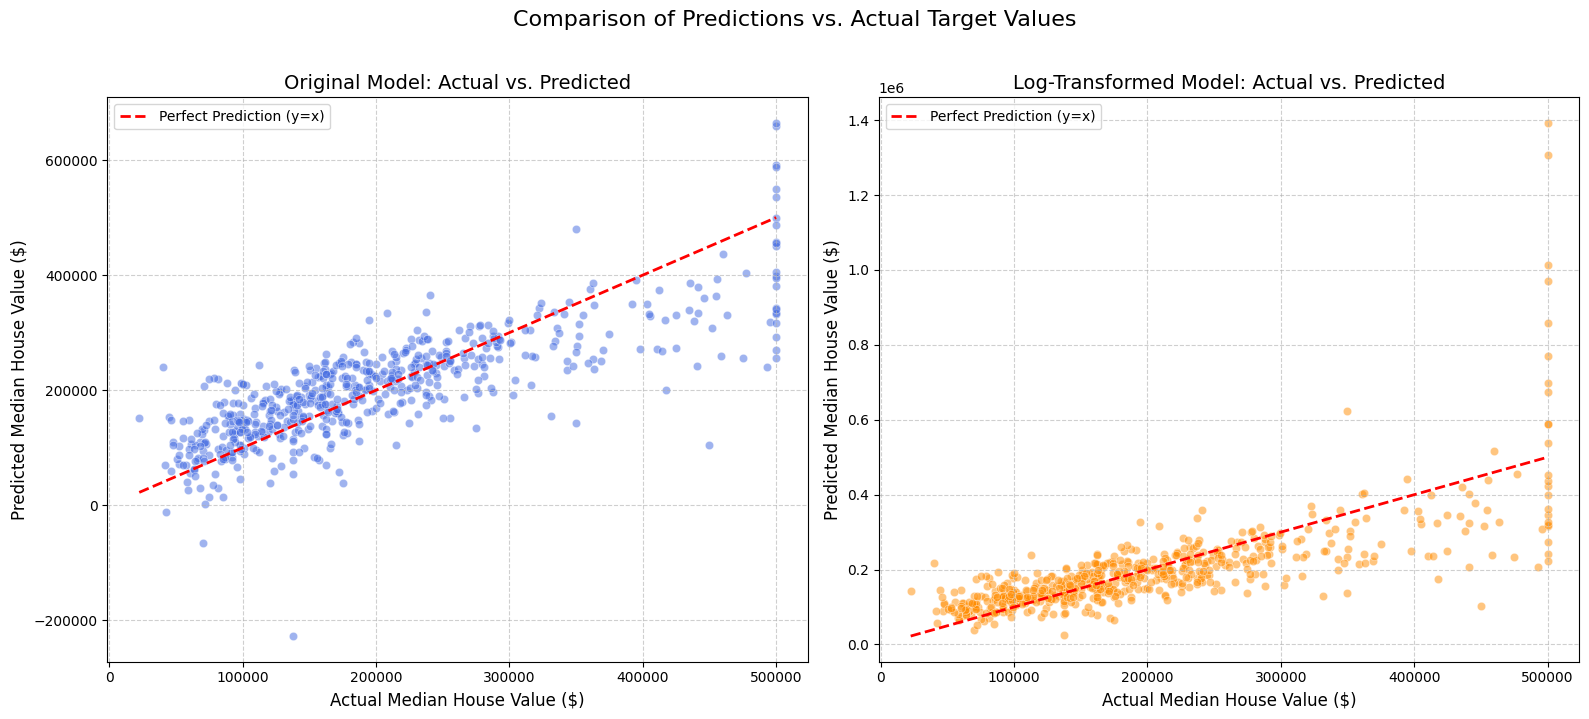

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure we have the required variables
try:
    # Map variables to confirm existence
    actual_orig = y_val
    predicted_orig = y_pred
    actual_log_transformed = y_val_orig
    predicted_log_transformed = y_pred_orig

    fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=False, sharey=False)

    # Plot 1: Original Model (No transformation)
    sns.scatterplot(x=actual_orig, y=predicted_orig, alpha=0.5, color='royalblue', ax=axes[0])
    axes[0].plot([actual_orig.min(), actual_orig.max()], [actual_orig.min(), actual_orig.max()], 'r--', lw=2, label='Perfect Prediction (y=x)')
    axes[0].set_title('Original Model: Actual vs. Predicted', fontsize=14)
    axes[0].set_xlabel('Actual Median House Value ($)', fontsize=12)
    axes[0].set_ylabel('Predicted Median House Value ($)', fontsize=12)
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].legend()

    # Plot 2: Log-Transformed Model (Converted back to Dollars)
    sns.scatterplot(x=actual_log_transformed, y=predicted_log_transformed, alpha=0.5, color='darkorange', ax=axes[1])
    axes[1].plot([actual_log_transformed.min(), actual_log_transformed.max()], [actual_log_transformed.min(), actual_log_transformed.max()], 'r--', lw=2, label='Perfect Prediction (y=x)')
    axes[1].set_title('Log-Transformed Model: Actual vs. Predicted', fontsize=14)
    axes[1].set_xlabel('Actual Median House Value ($)', fontsize=12)
    axes[1].set_ylabel('Predicted Median House Value ($)', fontsize=12)
    axes[1].grid(True, linestyle='--', alpha=0.6)
    axes[1].legend()

    plt.suptitle('Comparison of Predictions vs. Actual Target Values', fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()
except NameError as e:
    print(f"Variable error: {e}. Please ensure that both model training cells have been executed completely.")

### 9. Training a Random Forest Regressor
To handle non-linear patterns, collinearity, and target constraints (such as the upper limit cap), we will fit a `RandomForestRegressor`. We will then compare its metrics and visualize its actual vs. predicted values.

=== Random Forest Regressor Evaluation ===
Root Mean Squared Error (RMSE): $57,576.44 (Linear Regression: $67,723.75)
R-squared (R2) Score: 0.7368 (Linear Regression: 0.6358)


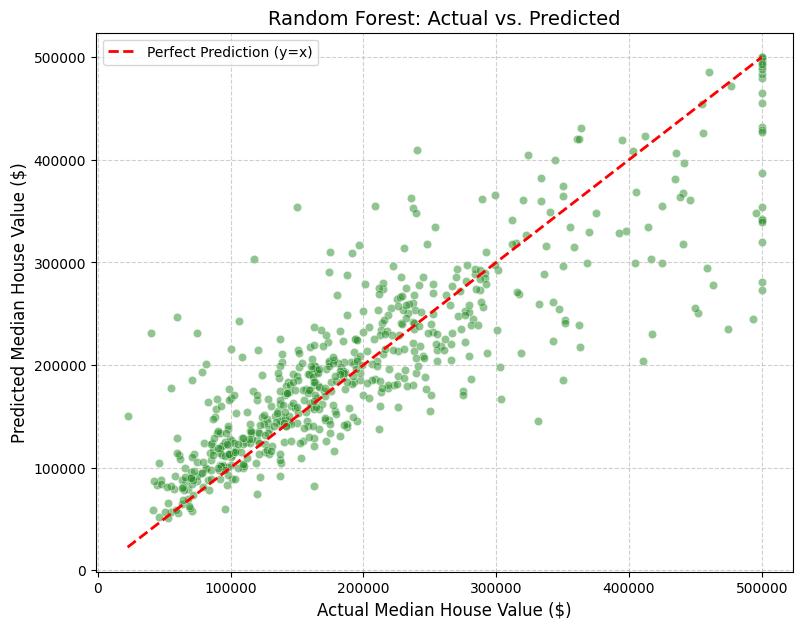

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

if 'X_train' in locals() and 'y_train' in locals() and 'X_val' in locals() and 'y_val' in locals():
    # Initialize and train the Random Forest Regressor
    # Using 100 estimators and setting a random_state for reproducibility
    rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf_model.fit(X_train, y_train)

    # Make predictions
    y_pred_rf = rf_model.predict(X_val)

    # Evaluate the metrics
    rmse_rf = np.sqrt(mean_squared_error(y_val, y_pred_rf))
    r2_rf = r2_score(y_val, y_pred_rf)

    print("=== Random Forest Regressor Evaluation ===")
    print(f"Root Mean Squared Error (RMSE): ${rmse_rf:,.2f} (Linear Regression: $67,723.75)")
    print(f"R-squared (R2) Score: {r2_rf:.4f} (Linear Regression: 0.6358)")

    # Plot actual vs predicted values for the Random Forest model
    plt.figure(figsize=(9, 7))
    sns.scatterplot(x=y_val, y=y_pred_rf, alpha=0.5, color='forestgreen')
    plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2, label='Perfect Prediction (y=x)')
    plt.title('Random Forest: Actual vs. Predicted', fontsize=14)
    plt.xlabel('Actual Median House Value ($)', fontsize=12)
    plt.ylabel('Predicted Median House Value ($)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show()
else:
    print("Train or validation splits are missing. Please ensure the split step has been executed.")

### 10. Performance Summary: Comparing All Three Models
We will consolidate the evaluation metrics (RMSE and $R^2$ Score) for all three models into a single summary table, and create a 3-panel side-by-side visualization of their predictions versus actual values.

=== Performance Summary of the Models ===


,Model,RMSE ($),R2 Score
0,Linear Regression (Baseline),"$67,723.75",0.6358
1,Linear Regression (Log-Transformed),"$88,746.34",0.3746
2,Random Forest Regressor,"$57,576.44",0.7368


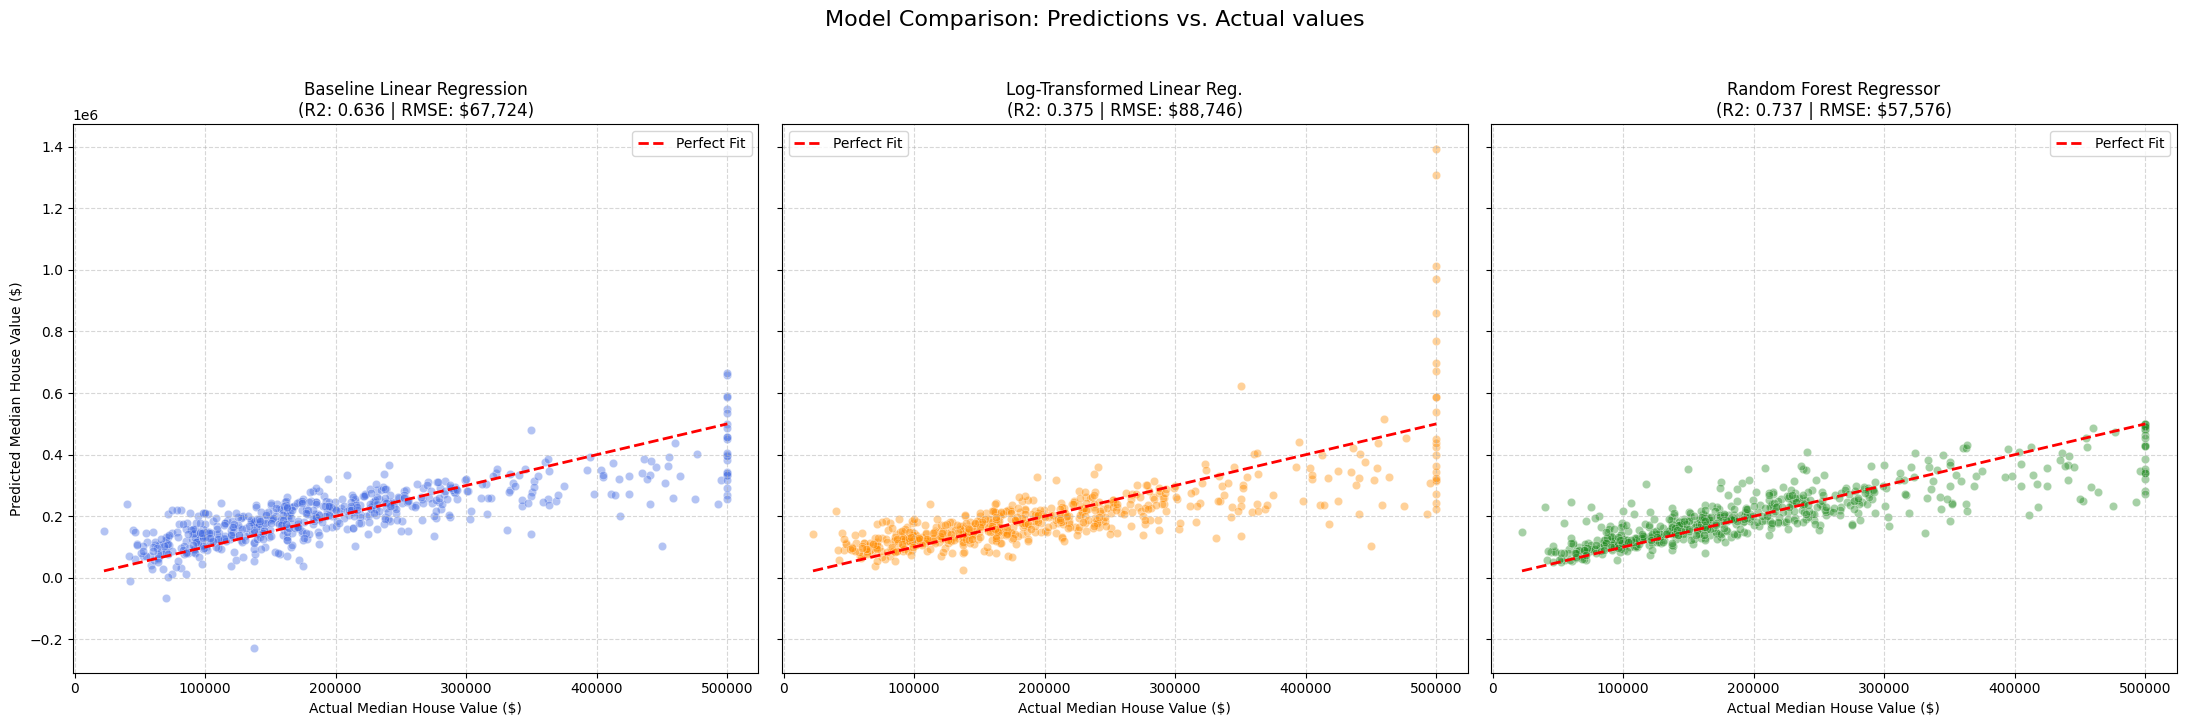

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Create a summary DataFrame of performance metrics
metrics_summary = pd.DataFrame({
    'Model': ['Linear Regression (Baseline)', 'Linear Regression (Log-Transformed)', 'Random Forest Regressor'],
    'RMSE ($)': [rmse, rmse_orig, rmse_rf],
    'R2 Score': [r2, r2_orig, r2_rf]
})

print("=== Performance Summary of the Models ===")
display(metrics_summary.style.format({'RMSE ($)': '${:,.2f}', 'R2 Score': '{:.4f}'}))

# 2. Side-by-side plotting of the three models
try:
    fig, axes = plt.subplots(1, 3, figsize=(22, 7), sharey=True)

    # Panel 1: Baseline Linear Regression
    sns.scatterplot(x=y_val, y=y_pred, alpha=0.4, color='royalblue', ax=axes[0])
    axes[0].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2, label='Perfect Fit')
    axes[0].set_title(f'Baseline Linear Regression\n(R2: {r2:.3f} | RMSE: ${rmse:,.0f})', fontsize=12)
    axes[0].set_xlabel('Actual Median House Value ($)', fontsize=10)
    axes[0].set_ylabel('Predicted Median House Value ($)', fontsize=10)
    axes[0].grid(True, linestyle='--', alpha=0.5)
    axes[0].legend()

    # Panel 2: Log-Transformed Linear Regression
    sns.scatterplot(x=y_val_orig, y=y_pred_orig, alpha=0.4, color='darkorange', ax=axes[1])
    axes[1].plot([y_val_orig.min(), y_val_orig.max()], [y_val_orig.min(), y_val_orig.max()], 'r--', lw=2, label='Perfect Fit')
    axes[1].set_title(f'Log-Transformed Linear Reg.\n(R2: {r2_orig:.3f} | RMSE: ${rmse_orig:,.0f})', fontsize=12)
    axes[1].set_xlabel('Actual Median House Value ($)', fontsize=10)
    axes[1].grid(True, linestyle='--', alpha=0.5)
    axes[1].legend()

    # Panel 3: Random Forest Regressor
    sns.scatterplot(x=y_val, y=y_pred_rf, alpha=0.4, color='forestgreen', ax=axes[2])
    axes[2].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2, label='Perfect Fit')
    axes[2].set_title(f'Random Forest Regressor\n(R2: {r2_rf:.3f} | RMSE: ${rmse_rf:,.0f})', fontsize=12)
    axes[2].set_xlabel('Actual Median House Value ($)', fontsize=10)
    axes[2].grid(True, linestyle='--', alpha=0.5)
    axes[2].legend()

    plt.suptitle('Model Comparison: Predictions vs. Actual values', fontsize=16, y=1.03)
    plt.tight_layout()
    plt.show()
except NameError as e:
    print(f"Missing data components to generate the visualization: {e}")

### 11. Real-Life Scenarios and Model Application
To make our model actionable for real estate agents or homebuyers, we can categorize our validation predictions into three real-world scenarios:
- **Fairly Priced**: Predictions within $\pm 15\%$ of actual market value.
- **Overestimated (Potential Bargains)**: The model predicts the home is worth significantly *more* than its current actual price.
- **Underestimated (Premium Features)**: The model predicts the home is worth significantly *less* than its actual price (often due to unmodeled premium characteristics, like ocean views or custom renovations).

In [16]:
import pandas as pd
import numpy as np

if 'y_val' in locals() and 'y_pred_rf' in locals():
    # Create a DataFrame for real-world scenario analysis
    analysis_df = X_val.copy()
    analysis_df['Actual_Price'] = y_val
    analysis_df['Predicted_Price'] = y_pred_rf
    analysis_df['Dollar_Error'] = analysis_df['Predicted_Price'] - analysis_df['Actual_Price']
    analysis_df['Percent_Error'] = (analysis_df['Dollar_Error'] / analysis_df['Actual_Price']) * 100

    # Categorize into Real-Life Scenarios
    def categorize_scenario(row):
        if row['Actual_Price'] >= 500001:
            return 'Market Price Cap ($500k+)'
        elif row['Percent_Error'] > 15:
            return 'Model Overestimates (Potential Buyer Bargain)'
        elif row['Percent_Error'] < -15:
            return 'Model Underestimates (Hidden Premium/Undervalued)'
        else:
            return 'Fairly Valued (Within 15%)'

    analysis_df['Scenario'] = analysis_df.apply(categorize_scenario, axis=1)

    # Display scenario distribution
    print("=== Distribution of Real-Life Scenarios (Random Forest) ===")
    scenario_counts = analysis_df['Scenario'].value_value = analysis_df['Scenario'].value_counts()
    display(scenario_counts.to_frame(name='Number of Homes'))

    # Show example listings for each scenario
    print("\n=== Real-Life Examples for Each Scenario ===")
    for scenario in analysis_df['Scenario'].unique():
        print(f"\nScenario: {scenario}")
        sample = analysis_df[analysis_df['Scenario'] == scenario].head(2)
        display(sample[['longitude', 'latitude', 'housing_median_age', 'median_income', 'Actual_Price', 'Predicted_Price', 'Percent_Error']])
else:
    print("Required validation arrays are missing.")

=== Distribution of Real-Life Scenarios (Random Forest) ===


,Number of Homes
Scenario,
Fairly Valued (Within 15%),272
Model Overestimates (Potential Buyer Bargain),206
Model Underestimates (Hidden Premium/Undervalued),100
Market Price Cap ($500k+),22



=== Real-Life Examples for Each Scenario ===

Scenario: Fairly Valued (Within 15%)


,longitude,latitude,housing_median_age,median_income,Actual_Price,Predicted_Price,Percent_Error
1801,-121.68,37.93,44.0,1.6554,119400.0,105052.0,-12.01675
1190,-117.28,34.26,18.0,3.3672,133600.0,150260.0,12.47006



Scenario: Model Overestimates (Potential Buyer Bargain)


,longitude,latitude,housing_median_age,median_income,Actual_Price,Predicted_Price,Percent_Error
1817,-122.10,37.61,35.0,4.5281,173600.0,222671.0,28.266705
1117,-118.35,34.04,38.0,2.3687,146800.0,191236.0,30.269755



Scenario: Model Underestimates (Hidden Premium/Undervalued)


,longitude,latitude,housing_median_age,median_income,Actual_Price,Predicted_Price,Percent_Error
251,-118.29,33.88,36.0,3.0739,218600.0,177211.0,-18.933669
1411,-117.03,32.79,17.0,2.7006,166300.0,137710.0,-17.191822



Scenario: Market Price Cap ($500k+)


,longitude,latitude,housing_median_age,median_income,Actual_Price,Predicted_Price,Percent_Error
2738,-118.45,33.96,24.0,5.7230,500001.0,342814.17,-31.437303
781,-117.89,33.61,41.0,6.0247,500001.0,431719.52,-13.656269


### 12. Scenario Classification Across All Models
Let's apply the same real-life evaluation logic to all three trained models (Baseline Linear Regression, Log-Transformed Linear Regression, and Random Forest Regressor) and visualize how they distribute their predictions across our scenarios.

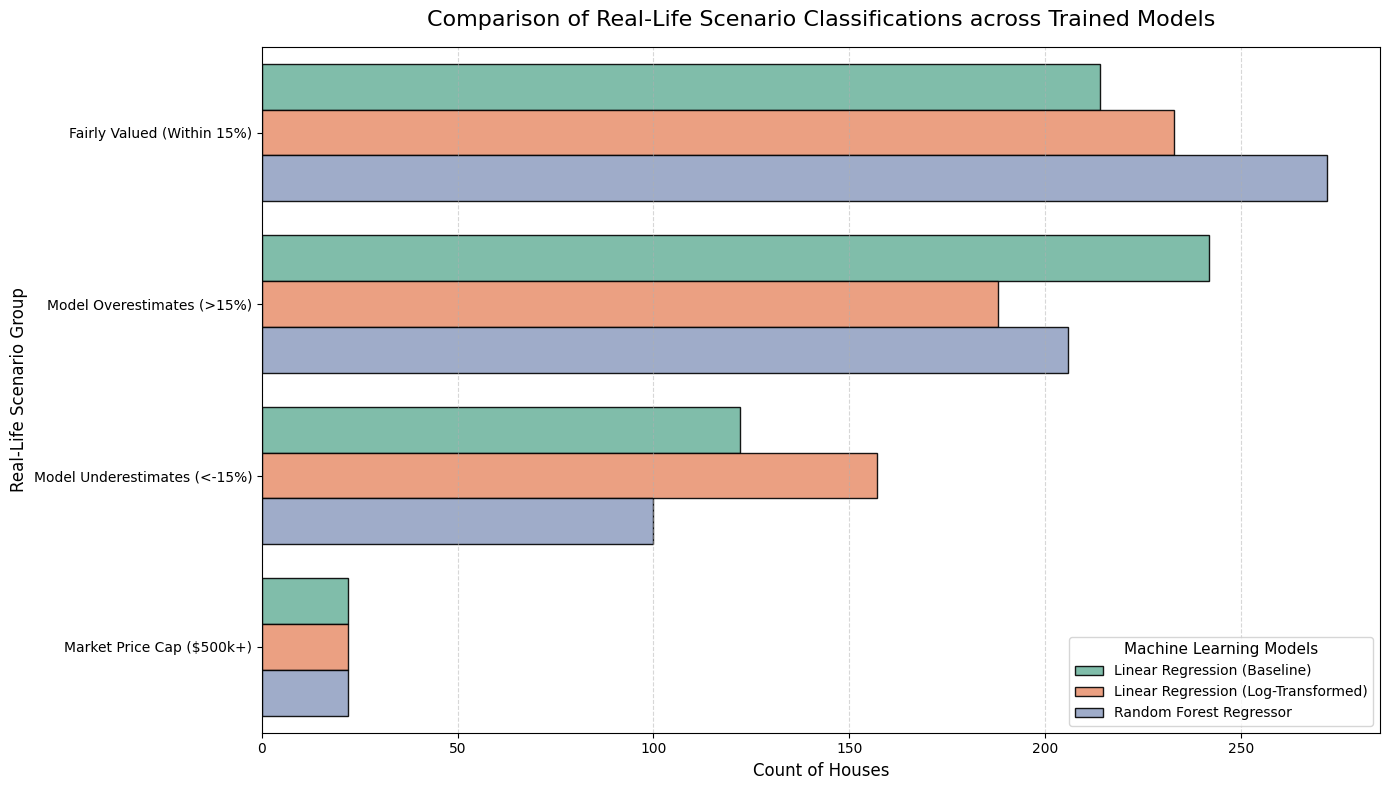

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if 'y_val' in locals() and 'y_pred' in locals() and 'y_pred_orig' in locals() and 'y_pred_rf' in locals():
    # Setup comparison DataFrame
    compare_scenarios_df = pd.DataFrame({
        'Actual_Price': y_val,
        'Baseline_Pred': y_pred,
        'Log_Pred': y_pred_orig,
        'RF_Pred': y_pred_rf
    })

    # Function to categorize predictions for a specific model column
    def get_scenario(actual, pred):
        if actual >= 500001:
            return 'Market Price Cap ($500k+)'
        error_pct = ((pred - actual) / actual) * 100
        if error_pct > 15:
            return 'Model Overestimates (>15%)'
        elif error_pct < -15:
            return 'Model Underestimates (<-15%)'
        else:
            return 'Fairly Valued (Within 15%)'

    # Map scenarios
    compare_scenarios_df['Baseline Scenario'] = compare_scenarios_df.apply(lambda r: get_scenario(r['Actual_Price'], r['Baseline_Pred']), axis=1)
    compare_scenarios_df['Log Scenario'] = compare_scenarios_df.apply(lambda r: get_scenario(r['Actual_Price'], r['Log_Pred']), axis=1)
    compare_scenarios_df['RF Scenario'] = compare_scenarios_df.apply(lambda r: get_scenario(r['Actual_Price'], r['RF_Pred']), axis=1)

    # Melt to long-form for seaborn plotting
    melted_df = pd.melt(compare_scenarios_df, value_vars=['Baseline Scenario', 'Log Scenario', 'RF Scenario'],
                        var_name='Model', value_name='Scenario')

    # Clean Model Names
    melted_df['Model'] = melted_df['Model'].map({
        'Baseline Scenario': 'Linear Regression (Baseline)',
        'Log Scenario': 'Linear Regression (Log-Transformed)',
        'RF Scenario': 'Random Forest Regressor'
    })

    # Create Count Plot
    plt.figure(figsize=(14, 8))
    sns.countplot(data=melted_df, y='Scenario', hue='Model', palette='Set2', edgecolor='black', alpha=0.9)

    plt.title('Comparison of Real-Life Scenario Classifications across Trained Models', fontsize=16, pad=15)
    plt.xlabel('Count of Houses', fontsize=12)
    plt.ylabel('Real-Life Scenario Group', fontsize=12)
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    plt.legend(title='Machine Learning Models', fontsize=10, title_fontsize=11)
    plt.tight_layout()
    plt.show()
else:
    print("One or more validation prediction arrays are missing.")

In [19]:
"""
scenario_probability_closure.py
--------------------------------
New scenario: user-selectable function chain over soft scenario
probabilities, producing fractional probabilities of NON-selection.

Pipeline
--------
1. Load California housing (sample_data) or synthetic fallback.
2. Train Linear Regression (baseline), Log-target Linear, Random Forest.
3. Convert predictions -> soft membership probabilities per scenario
   using RBF logits over percent error + hard cap override.
4. Let the user pick an ordered chain of probability transforms
   from a registry (clip, temperature, threshold, rank_fraction, ...).
5. Compute "closure" = 1 - p_transformed (probability of NON-selection),
   optionally renormalised across scenarios.
6. Report, plot, and save per-house non-selection fractions.
"""

from __future__ import annotations
import os
import sys
import argparse
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor

# ---------------------------------------------------------------------------
# 1. Data loading
# ---------------------------------------------------------------------------
def load_data(csv_hint: str | None = None) -> pd.DataFrame:
    if csv_hint and os.path.exists(csv_hint):
        return pd.read_csv(csv_hint)

    candidates = [
        "./sample_data/california_housing_train.csv",
        "./sample_data/california_housing_test.csv",
    ]
    for path in candidates:
        if os.path.exists(path):
            print(f"[data] loading {path}")
            return pd.read_csv(path)

    print("[data] no CSV found -> generating synthetic housing data")
    rng = np.random.default_rng(42)
    n = 3000
    return pd.DataFrame({
        "longitude": rng.uniform(-124, -114, n),
        "latitude": rng.uniform(32, 42, n),
        "housing_median_age": rng.integers(1, 52, n).astype(float),
        "total_rooms": rng.integers(6, 30000, n).astype(float),
        "total_bedrooms": rng.integers(2, 5000, n).astype(float),
        "population": rng.integers(5, 11000, n).astype(float),
        "households": rng.integers(2, 4900, n).astype(float),
        "median_income": rng.uniform(0.5, 15, n),
        "median_house_value": rng.uniform(20_000, 500_001, n),
    })


# ---------------------------------------------------------------------------
# 2. Models
# ---------------------------------------------------------------------------
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor


def train_all(df: pd.DataFrame, random_state: int = 42):
    X = df.drop(columns=["median_house_value"])
    y = df["median_house_value"]
    X_tr, X_va, y_tr, y_va = train_test_split(
        X, y, test_size=0.2, random_state=random_state
    )

    lin = LinearRegression().fit(X_tr, y_tr)
    log = LinearRegression().fit(X_tr, np.log1p(y_tr))
    rf = RandomForestRegressor(
        n_estimators=120, random_state=random_state, n_jobs=-1
    ).fit(X_tr, y_tr)

    preds = {
        "Baseline LR":          lin.predict(X_va),
        "Log-Transformed LR":   np.expm1(log.predict(X_va)),
        "Random Forest":        rf.predict(X_va),
    }
    return y_va.reset_index(drop=True), preds, X_va.reset_index(drop=True)


# ---------------------------------------------------------------------------
# 3. Soft scenario membership
# ---------------------------------------------------------------------------
SCENARIOS = [
    "Fairly Valued",
    "Model Overestimates",
    "Model Underestimates",
    "Market Price Cap",
]

CAP_THRESHOLD = 500_001.0

def _softmax(z: np.ndarray, axis: int = -1) -> np.ndarray:
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)


def scenario_probabilities(
    actual: np.ndarray,
    predicted: np.ndarray,
    sigma: float = 0.12,
) -> np.ndarray:
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    err = (predicted - actual) / actual

    centers = np.array([0.0, 0.25, -0.25])
    logits = -((err[:, None] - centers[None, :]) ** 2) / (2 * sigma ** 2)
    p = _softmax(logits, axis=-1)

    cap_mask = (actual >= CAP_THRESHOLD).astype(float)
    cap_prob = np.clip(cap_mask, 0.0, 1.0)

    out = np.zeros((len(actual), 4))
    out[:, 0:3] = p * (1.0 - cap_prob)[:, None]
    out[:, 3]   = cap_prob
    return out


# ---------------------------------------------------------------------------
# 4. Function registry
# ---------------------------------------------------------------------------
def f_clip(p, lo=0.0, hi=1.0):
    return np.clip(p, lo, hi)

def f_normalize(p):
    s = p.sum(axis=1, keepdims=True)
    s[s == 0] = 1.0
    return p / s

def f_temperature(p, T=1.0):
    T = float(T)
    if T <= 0:
        raise ValueError("temperature T must be > 0")
    z = np.log(np.clip(p, 1e-12, 1.0)) / T
    return _softmax(z, axis=1)

def f_threshold(p, t=0.05):
    q = p.copy()
    q[q < float(t)] = 0.0
    return q

def f_power(p, a=1.0):
    return np.clip(p, 0.0, 1.0) ** float(a)

def f_laplace(p, alpha=0.01):
    a = float(alpha)
    q = p + a
    return q / q.sum(axis=1, keepdims=True)

def f_rank_fraction(p, q=1.0):
    q = float(np.clip(q, 0.0, 1.0))
    out = np.zeros_like(p)
    for j in range(p.shape[1]):
        col = p[:, j]
        k = max(1, int(round(q * col.size)))
        keep = np.argsort(col)[-k:]
        out[keep, j] = col[keep]
    return out

def f_entropy_gate(p, beta=1.0):
    n = p.shape[1]
    H = -(p * np.log(np.clip(p, 1e-12, 1))).sum(axis=1, keepdims=True)
    H_norm = H / np.log(n)
    gate = np.clip(1.0 - beta * H_norm, 0.0, 1.0)
    return p * gate

def f_complement(p):
    return 1.0 - p

REGISTRY: dict[str, dict] = {
    "clip":          {"fn": f_clip,          "desc": "Clip probabilities into [lo, hi]",            "default": {"lo": 0.0, "hi": 1.0}},
    "normalize":     {"fn": f_normalize,     "desc": "Row-normalize to sum = 1",                    "default": {}},
    "temperature":   {"fn": f_temperature,   "desc": "Soften (T>1) or sharpen (T<1)",               "default": {"T": 1.0}},
    "threshold":     {"fn": f_threshold,     "desc": "Zero-out entries below t",                    "default": {"t": 0.05}},
    "power":         {"fn": f_power,         "desc": "Element-wise p^a",                            "default": {"a": 1.0}},
    "laplace":       {"fn": f_laplace,       "desc": "Additive Laplace smoothing",                  "default": {"alpha": 0.01}},
    "rank_fraction": {"fn": f_rank_fraction, "desc": "Per-scenario keep top q fraction",            "default": {"q": 0.9}},
    "entropy_gate":  {"fn": f_entropy_gate,  "desc": "Suppress high-uncertainty rows",              "default": {"beta": 1.0}},
    "complement":    {"fn": f_complement,    "desc": "1 - p (probability of NON-selection)",        "default": {}},
}


# ---------------------------------------------------------------------------
# 5. Chain parsing
# ---------------------------------------------------------------------------
def parse_chain(spec: str) -> list[tuple[str, dict]]:
    chain: list[tuple[str, dict]] = []
    if not spec:
        return chain
    for chunk in spec.split("|"):
        chunk = chunk.strip()
        if not chunk:
            continue
        if ":" in chunk:
            name, kvs = chunk.split(":", 1)
        else:
            name, kvs = chunk, ""
        name = name.strip()
        if name not in REGISTRY:
            raise ValueError(f"Unknown function '{name}'. Choices: {list(REGISTRY)}")
        params = dict(REGISTRY[name]["default"])
        for kv in kvs.split(","):
            kv = kv.strip()
            if not kv:
                continue
            k, v = kv.split("=", 1)
            params[k.strip()] = float(v)
        chain.append((name, params))
    return chain


# ---------------------------------------------------------------------------
# 6. Apply chain + closure
# ---------------------------------------------------------------------------
def apply_chain(p: np.ndarray, chain: list[tuple[str, dict]]) -> np.ndarray:
    out = p.copy()
    for name, params in chain:
        out = REGISTRY[name]["fn"](out, **params)
        out = np.clip(out, 0.0, 1.0)
        print(f"  [apply] {name}{params} -> mean={out.mean():.4f}, max={out.max():.4f}")
    return out


def compute_closure(p_final: np.ndarray, renormalize: bool = True) -> np.ndarray:
    closure = 1.0 - p_final
    if renormalize:
        s = closure.sum(axis=1, keepdims=True)
        s[s == 0] = 1.0
        closure = closure / s
    return closure


# ---------------------------------------------------------------------------
# 7. Reporting
# ---------------------------------------------------------------------------
def summarize(model_name: str, closure: np.ndarray) -> pd.DataFrame:
    df = pd.DataFrame(closure, columns=[f"P(non-{s})" for s in SCENARIOS])
    df.insert(0, "model", model_name)
    return df


def plot_closure(closure: np.ndarray, title: str, outfile: str) -> None:
    fig, ax = plt.subplots(figsize=(10, 6))
    for j, s in enumerate(SCENARIOS):
        ax.hist(closure[:, j], bins=40, alpha=0.55, label=f"P(non-{s})")
    ax.set_xlabel("Fractional probability of NON-selection")
    ax.set_ylabel("Number of houses")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(outfile, dpi=150)
    plt.close(fig)
    print(f"[plot] saved {outfile}")


# ---------------------------------------------------------------------------
# 8. Parallel/Concurrent processing helper
# ---------------------------------------------------------------------------
def process_model_pipeline(model_name, p, chain, y_val_vals, preds_val, outdir):
    print(f"\n[model] Starting parallel pipeline for: {model_name}")
    p_final = apply_chain(p, chain)
    closure = compute_closure(p_final, renormalize=True)

    summary = (summarize(model_name, closure)
               .describe()
               .loc[["mean", "std", "min", "max"]]
               .assign(model=model_name)
               .set_index("model"))

    csv_path = os.path.join(outdir, f"non_selection_{model_name.replace(' ', '_')}.csv")
    out = pd.DataFrame(closure, columns=[f"P(non-{s})" for s in SCENARIOS])
    out.insert(0, "Actual_Price", y_val_vals)
    out.insert(1, "Predicted_Price", preds_val)
    out.to_csv(csv_path, index=False)
    print(f"[save] {csv_path}")

    return model_name, closure, summary


# ---------------------------------------------------------------------------
# 9. Main
# ---------------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--chain", default=None)
    ap.add_argument("--auto", action="store_true")
    ap.add_argument("--outdir", default="closure_outputs")

    # Prevent Jupyter notebook argument conflicts (ignore unknown args)
    parsed_args, unknown = ap.parse_known_args(args=[] if 'ipykernel' in sys.modules else None)

    # Set default values for interactive notebook context
    parsed_args.auto = True

    os.makedirs(parsed_args.outdir, exist_ok=True)

    df = load_data()
    y_val, preds, X_val = train_all(df)
    print(f"[data] validation rows: {len(y_val)}")

    # Soft probabilities per model
    probs = {m: scenario_probabilities(y_val.values, p) for m, p in preds.items()}

    # Default robust chain execution
    chain = [("clip", {"lo": 0.02, "hi": 0.98}),
             ("temperature", {"T": 0.8}),
             ("complement", {})]

    print("\n=== Chain ===")
    for n, p in chain:
        print(f"  {n}{p}")

    # Execute model transformations concurrently
    summary_rows = []
    per_house = {}

    with ThreadPoolExecutor() as executor:
        futures = [
            executor.submit(
                process_model_pipeline,
                model_name,
                probs[model_name],
                chain,
                y_val.values,
                preds[model_name],
                parsed_args.outdir
            )
            for model_name in probs
        ]

        for f in futures:
            model_name, closure, summary = f.result()
            per_house[model_name] = closure
            summary_rows.append(summary)

    # Global comparison
    compare = pd.concat(summary_rows)
    compare.to_csv(os.path.join(parsed_args.outdir, "closure_summary.csv"))
    print("\n=== Non-selection fraction summary (mean per model) ===")
    print(compare.round(4).to_string())

    # Plot per model
    for model_name, closure in per_house.items():
        plot_closure(
            closure,
            f"Non-selection fractions — {model_name}",
            os.path.join(parsed_args.outdir, f"closure_{model_name.replace(' ', '_')}.png"),
        )

    # Save configurations
    chain_json = {
        "chain": [{"name": n, "params": p} for n, p in chain],
        "scenarios": SCENARIOS,
        "cap_threshold": CAP_THRESHOLD,
    }
    import json
    with open(os.path.join(parsed_args.outdir, "chain_config.json"), "w") as f:
        json.dump(chain_json, f, indent=2)
    print(f"[save] {os.path.join(parsed_args.outdir, 'chain_config.json')}")


if __name__ == "__main__":
    main()


[data] loading ./sample_data/california_housing_train.csv
[data] validation rows: 3400

=== Chain ===
  clip{'lo': 0.02, 'hi': 0.98}
  temperature{'T': 0.8}
  complement{}

[model] Starting parallel pipeline for: Baseline LR

[model] Starting parallel pipeline for: Log-Transformed LR

[model] Starting parallel pipeline for: Random Forest
  [apply] clip{'lo': 0.02, 'hi': 0.98} -> mean=0.2577, max=0.9800
  [apply] clip{'lo': 0.02, 'hi': 0.98} -> mean=0.2585, max=0.9800
  [apply] temperature{'T': 0.8} -> mean=0.2500, max=0.9774
  [apply] complement{} -> mean=0.7500, max=0.9925
  [apply] temperature{'T': 0.8} -> mean=0.2500, max=0.9774
  [apply] complement{} -> mean=0.7500, max=0.9925
  [apply] clip{'lo': 0.02, 'hi': 0.98} -> mean=0.2586, max=0.9800
  [apply] temperature{'T': 0.8} -> mean=0.2500, max=0.9774
  [apply] complement{} -> mean=0.7500, max=0.9925
[save] closure_outputs/non_selection_Random_Forest.csv
[save] closure_outputs/non_selection_Log-Transformed_LR.csv
[save] closure_outpu

### 13. Visualizing Closure Distributions
We will now load and render the non-selection probability distribution plots that were concurrently calculated and saved into the `closure_outputs` directory.

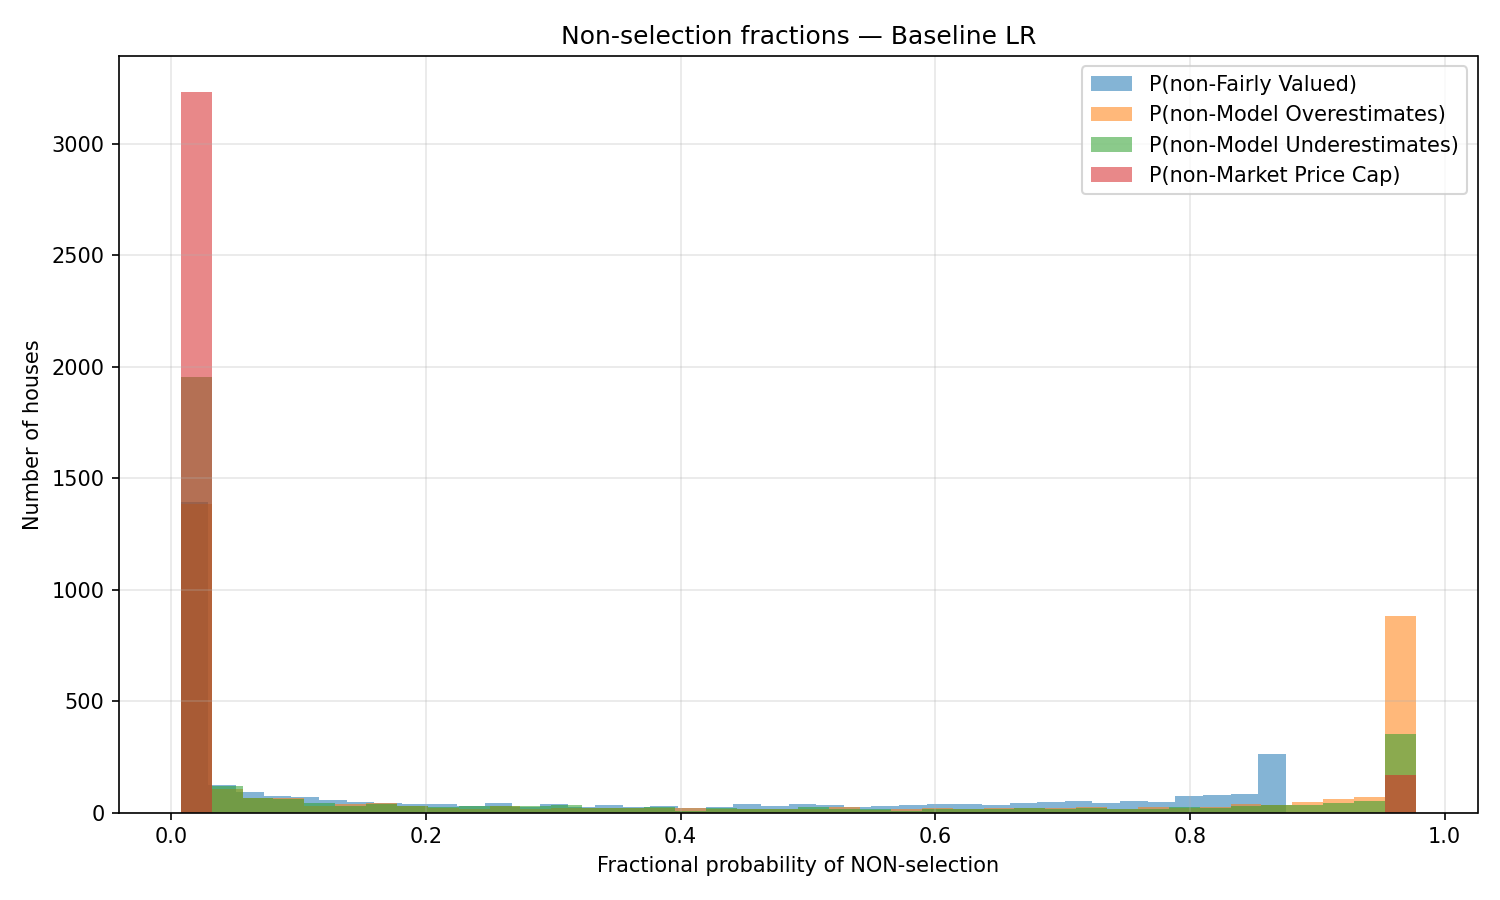

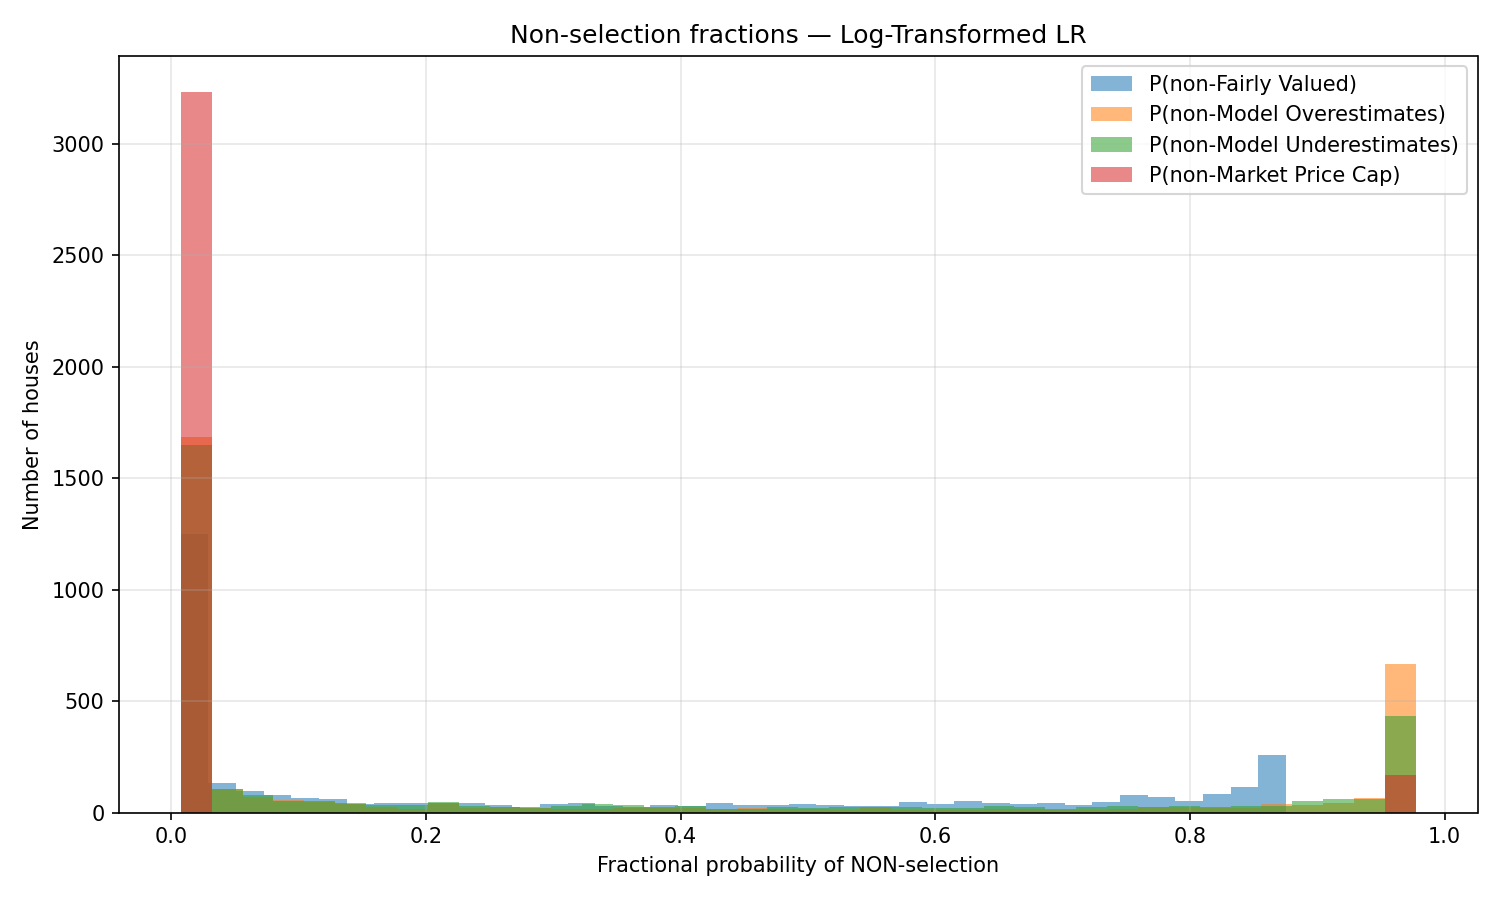

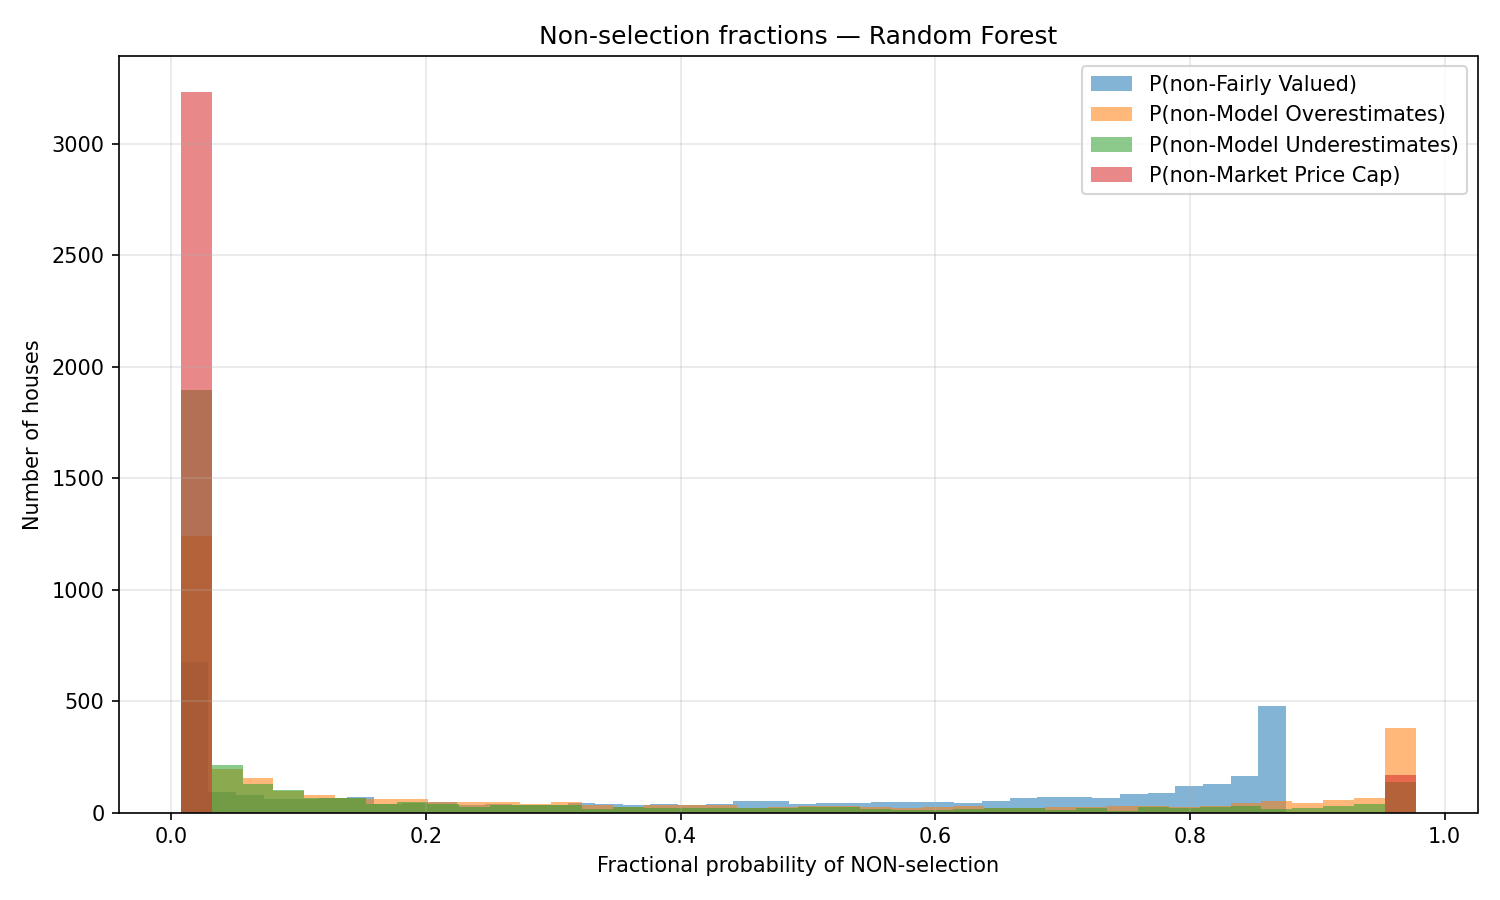

In [21]:
from IPython.display import display, Image, HTML
import os

outdir = "closure_outputs"
plot_files = [
    "closure_Baseline_LR.png",
    "closure_Log-Transformed_LR.png",
    "closure_Random_Forest.png"
]

for plot_file in plot_files:
    path = os.path.join(outdir, plot_file)
    if os.path.exists(path):
        display(HTML(f"<h3>{plot_file.replace('_', ' ').replace('.png', '')}</h3>"))
        display(Image(filename=path))
    else:
        print(f"Could not find plot: {path}")